# How VLMs Plan What's Next: a hands-on tour

This notebook lets you see two steps of the mechanism on your own images.

1. **Binding.** At the shape token of the question, a few *binding heads* match the requested shape against the image and form a pointer to the matching panel.
2. **Relay.** At the colon token, where the answer is produced, *relay heads* carry that pointer over from the shape token.

At the end you can **try your own patch**: copy any component, at any token and layer, from one run into another, and see what the model answers.

Run the cells from top to bottom. The first cell loads Qwen3-VL-8B-Instruct, which needs a GPU with 48 GB of memory.

In [1]:
import sys
sys.path.insert(0, ".")                      # run this notebook from the repository folder

from utils.model import load_model
from utils.dataset import SHAPES, LETTERS, draw_strip, one_answer_question, run_one_answer, outcome_letters, explain
from utils.patching import Patch, make_patch, run_model, run_patch, run_patches
from utils.heads import HEADS, random_like
from utils.plotting import show, show_attention, show_text_attention

model = load_model()                         # Qwen3-VL-8B-Instruct, FP32

## 1. Make your own data

An image is a row of panels. Each panel holds one shape with one letter inside it. The question names a shape, and the model answers with the letter inside that shape.

Change the shapes and letters below to anything you like.

shapes:  ('star', 'square', 'circle', 'triangle', 'diamond', 'plus', 'heart')
letters: ABCDEFGHKMNPRSTUVWXYZ


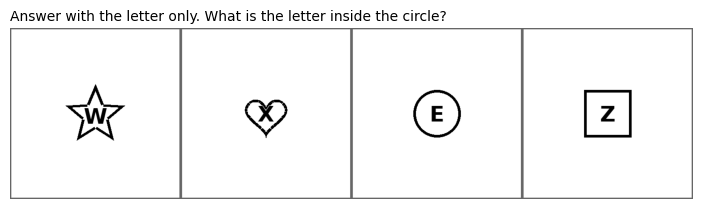

the model answers:  E


In [2]:
print("shapes: ", SHAPES)
print("letters:", "".join(LETTERS))

image = draw_strip(shapes=["star", "heart", "circle", "square"], letters=["W", "X", "E", "Z"])
question = one_answer_question("circle")
show(image, titles=[question])

run = run_model(model, image, question)      # the prompt ends with "Answer:", and we read the next token
print("the model answers:", run.answer)

## 2. A source run and a target run

Every experiment uses two runs. We copy one internal state from the **source** run into the **target** run, and read what the target answers. Nothing else in the target changes.

The two images below hold the same four shapes in different orders, with different letters, and the two questions ask for different shapes. They are built so that each thing a patch could move gives a different letter. That way the target's answer tells us what the patched state carried.

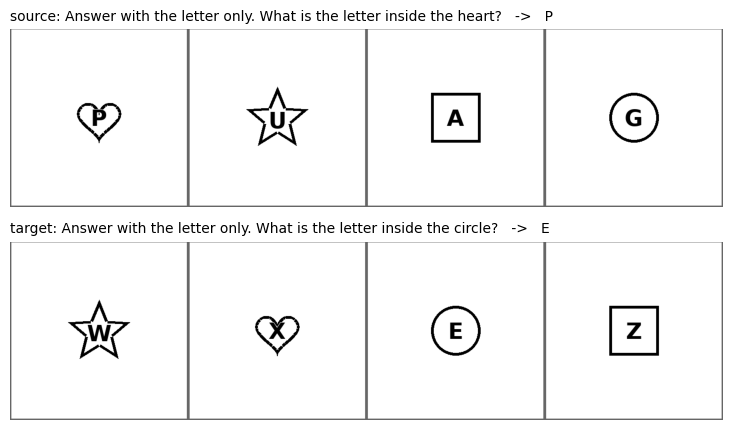

if the target answers E:  T: the target's own answer (nothing changed)
if the target answers P:  D: the source's answer (the answer itself was copied)
if the target answers W:  K: the target's letter at the panel the source points to (the pointer moved)
if the target answers X:  P: the target's letter inside the shape the source asks for (the request moved)
if the target answers Z:  R: the target's letter where the source image holds the target's shape (the layout moved)
if the target answers A:  C: the source's letter at the panel the target points to (the image content moved)


In [3]:
source_side = {"shapes": ["heart", "star", "square", "circle"], "letters": ["P", "U", "A", "G"], "ask": "heart"}
target_side = {"shapes": ["star", "heart", "circle", "square"], "letters": ["W", "X", "E", "Z"], "ask": "circle"}

source = run_one_answer(model, source_side)  # runs the model and names two tokens: "shape" and "colon"
target = run_one_answer(model, target_side)
show(source.image, target.image, titles=[f"source: {source.question}   ->  {source.answer}",
                                         f"target: {target.question}   ->  {target.answer}"])

letters = outcome_letters(source_side, target_side)
for name, letter in letters.items():
    print(f"if the target answers {letter}:  {explain(' ' + letter, letters)}")

## 3. Binding

The model finds the answer early. At the **shape token** of the question (here the word *circle*), long before the answer is written, the binding heads already attend to the panel that holds that shape.

the 16 binding heads (layer, head): [(18, 15), (21, 11), (17, 4), (19, 27), (15, 9), (19, 24), (21, 18), (15, 11), (15, 2), (17, 7), (20, 29), (21, 8), (16, 27), (20, 15), (17, 15), (18, 11)]


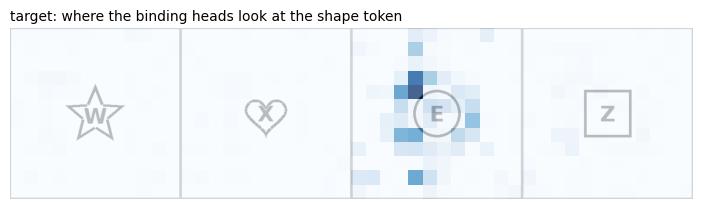

share of image attention per panel: 4%  3%  85%  8%


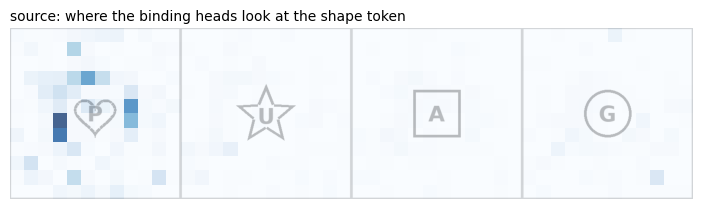

share of image attention per panel: 75%  8%  7%  10%


In [4]:
print("the 16 binding heads (layer, head):", HEADS["binding"])
show_attention(target, HEADS["binding"], "shape", title="target: where the binding heads look at the shape token")
show_attention(source, HEADS["binding"], "shape", title="source: where the binding heads look at the shape token")

These heads do more than look. Their **outputs** hold a pointer to the panel. To test this, we copy the outputs of the 16 binding heads at the shape token from the source into the target. The source points to its first panel, so the target should now answer with *its own* letter in the first panel (outcome **K**).

The control uses the same number of random heads from the same layers.

In [5]:
patch = make_patch(source, target, component="head_output", token="shape", heads=HEADS["binding"])
answer = run_patch(model, target, patch)
print("binding heads:", answer, "->", explain(answer, letters))

control = make_patch(source, target, "head_output", "shape", heads=random_like(HEADS["binding"], seed=0))
answer = run_patch(model, target, control)
print("random heads: ", answer, "->", explain(answer, letters))

binding heads:  W -> K: the target's letter at the panel the source points to (the pointer moved)
random heads:   E -> T: the target's own answer (nothing changed)


The pointer is built from two inputs. The heads' **queries** carry the shape that is asked for, and the **image keys** they read carry the layout of the image. Patching each one alone moves only that part:

In [6]:
answer = run_patch(model, target, make_patch(source, target, "query", "shape", heads=HEADS["query"]))
print("queries of the query heads:      ", answer, "->", explain(answer, letters))

answer = run_patch(model, target, make_patch(source, target, "image_keys", "shape", heads=HEADS["key"]))
print("image keys read by the key heads:", answer, "->", explain(answer, letters))

queries of the query heads:        X -> P: the target's letter inside the shape the source asks for (the request moved)
image keys read by the key heads:  Z -> R: the target's letter where the source image holds the target's shape (the layout moved)


## 4. Relay

The pointer is formed at the shape token, but the answer is written after the colon token at the end of the prompt. The **relay heads** carry it there. At the colon token they read the text tokens of the question, mostly the shape token:

the 16 relay heads (layer, head): [(22, 10), (22, 11), (35, 25), (23, 26), (25, 15), (19, 21), (34, 28), (23, 0), (20, 2), (20, 3), (23, 3), (25, 12), (28, 22), (21, 19), (22, 3), (22, 0)]


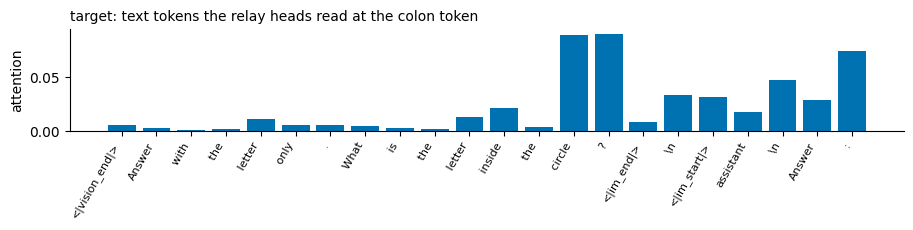

In [7]:
print("the 16 relay heads (layer, head):", HEADS["relay"])
show_text_attention(target, HEADS["relay"], "colon", title="target: text tokens the relay heads read at the colon token")

We now let the relay heads of the target read the source's **values** at those tokens (the shape token through the token before the colon), with their attention unchanged. If the values carry the pointer, the target answers **K** again. If we instead block the relay heads from those tokens, the target no longer gives its own answer.

In [8]:
text_tokens = list(range(target.token("shape"), target.token("colon")))     # shape token ... token before the colon

patch = make_patch(source, target, "values", "colon", heads=HEADS["relay"], positions=text_tokens)
answer = run_patch(model, target, patch)
print("relay heads read the source's values:", answer, "->", explain(answer, letters))

blocked = Patch().block(HEADS["relay"], tokens=[target.token("colon")], positions=text_tokens)
answer = run_patch(model, target, blocked)
print("relay heads blocked from the text:   ", answer, "->", explain(answer, letters))

relay heads read the source's values:  W -> K: the target's letter at the panel the source points to (the pointer moved)


relay heads blocked from the text:     Z -> R: the target's letter where the source image holds the target's shape (the layout moved)


## 5. Try your own patch

Pick a component, a token, and a layer, and copy it from the source into the target.

- `COMPONENT`: `"residual"`, `"mlp"`, `"head_output"`, `"query"`, `"image_keys"`, `"image_values"`, `"keys"` or `"values"`. The same component is read from the source and written into the target.
- `TARGET_TOKEN` and `SOURCE_TOKEN`: any text token after the image. Use a name (`"shape"`, `"colon"`) or a position from the list printed below. They do not have to be the same token.
- `TARGET_LAYER` and `SOURCE_LAYER`: for `"residual"` and `"mlp"`. Layer 0 is the input of the first block.
- `HEADS` and `SOURCE_HEADS`: for the attention components, lists of `(layer, head)`.

In [9]:
print("text tokens of the target (position, token):")
print(target.text_tokens())

text tokens of the target (position, token):
[(580, '<|vision_end|>'), (581, 'Answer'), (582, ' with'), (583, ' the'), (584, ' letter'), (585, ' only'), (586, '.'), (587, ' What'), (588, ' is'), (589, ' the'), (590, ' letter'), (591, ' inside'), (592, ' the'), (593, ' circle'), (594, '?'), (595, '<|im_end|>'), (596, '\n'), (597, '<|im_start|>'), (598, 'assistant'), (599, '\n'), (600, 'Answer'), (601, ':')]


In [10]:
COMPONENT    = "residual"
TARGET_TOKEN = "colon"
SOURCE_TOKEN = "colon"
TARGET_LAYER = 24
SOURCE_LAYER = 24
HEADS_TO_PATCH = HEADS["binding"]            # used only by the attention components
SOURCE_HEADS   = None                        # None means the same heads as HEADS_TO_PATCH

patch = make_patch(source, target, COMPONENT, token=TARGET_TOKEN, source_token=SOURCE_TOKEN,
                   layer=TARGET_LAYER, source_layer=SOURCE_LAYER, heads=HEADS_TO_PATCH, source_heads=SOURCE_HEADS,
                   positions=text_tokens)   # positions are used only by "keys" and "values"
answer = run_patch(model, target, patch)
print("the target answers:", answer, "->", explain(answer, letters))

the target answers:  W -> K: the target's letter at the panel the source points to (the pointer moved)


A patch is quick, so you can sweep it. Below we patch the residual at the colon token at every layer. Early layers change nothing, a band of middle layers moves the pointer (**K**), and late layers copy the source's answer (**D**). This is the first experiment of the paper, on one pair.

In [11]:
layers = range(len(model.model.language_model.layers) + 1)
patches = [make_patch(source, target, "residual", "colon", layer=layer) for layer in layers]
answers = run_patches(model, target, patches)["answers"]
for layer, answer in zip(layers, answers):
    print(f"layer {layer:2d}: {answer}   {explain(answer, letters)}")

layer  0:  E   T: the target's own answer (nothing changed)
layer  1:  E   T: the target's own answer (nothing changed)
layer  2:  E   T: the target's own answer (nothing changed)
layer  3:  E   T: the target's own answer (nothing changed)
layer  4:  E   T: the target's own answer (nothing changed)
layer  5:  E   T: the target's own answer (nothing changed)
layer  6:  E   T: the target's own answer (nothing changed)
layer  7:  E   T: the target's own answer (nothing changed)
layer  8:  E   T: the target's own answer (nothing changed)
layer  9:  E   T: the target's own answer (nothing changed)
layer 10:  E   T: the target's own answer (nothing changed)
layer 11:  E   T: the target's own answer (nothing changed)
layer 12:  E   T: the target's own answer (nothing changed)
layer 13:  E   T: the target's own answer (nothing changed)
layer 14:  E   T: the target's own answer (nothing changed)
layer 15:  E   T: the target's own answer (nothing changed)
layer 16:  E   T: the target's own answe

## Where to go next

Each folder of the repository reproduces one part of the paper on the full set of pairs: `binding/`, `relay/`, `progress/`, `gaze/`, `language/`, and `generalization/`. Every file in a `main_experiments/` folder is one experiment and runs on its own, for example:

```bash
python binding/main_experiments/03_binding_heads.py --num_pairs 100
```